# 01 — Veri Temini, Format Dönüşümü ve Veri Büyüklüğü Analizi (Öğrenci 1)

**Araştırma sorusu:** Veri büyüdükçe klasik analiz yaklaşımı (pandas + CSV) ne zaman yetersiz kalıyor, ve neden?

Bu notebook ölçüm yapmaz; ölçümler tekrar üretilebilir scriptlerle alınmış ve `reports/results/` altına yazılmıştır. Burada sonuçlar okunur, görselleştirilir ve **yorumlanır**.

| Adım | Script | Çıktı |
|---|---|---|
| T1.1 Veri temini | `python -m src.ingest` | `data/raw/` (5 parquet + zone lookup) |
| T1.2 Veri sözlüğü | `python -m src.dictionary_stats` | `docs/data_dictionary.md` |
| T1.3 Boyut setleri | `python -m src.build_sizes` | `D:\BVAVeri\processed\` + `size_sets_manifest.csv` |
| T1.4 Okuma/bellek ölçümü | `python -m src.benchmark_io` (+ `--startup`) | `io_benchmark.csv`, `spark_startup.csv` |
| T1.5 Grafikler | bu notebook (`src/plots_io.py`) | `reports/figures/*.png` |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config, plots_io as pio

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
results = config.RESULTS_DIR
manifest = pd.read_csv(results / "size_sets_manifest.csv")
summary = pd.read_csv(results / "io_benchmark.csv")
startup = pd.read_csv(results / "spark_startup.csv")
startup_s = startup.loc[startup["status"] == "ok", "seconds"].mean()
print(f"Ölçüm kombinasyonu: {len(summary)}  |  Spark oturum açılışı: {startup_s:.1f} sn (3 tekrar ort.)")

Ölçüm kombinasyonu: 85  |  Spark oturum açılışı: 11.4 sn (3 tekrar ort.)


## 1. Veri: NYC TLC Yellow Taxi, 2026 Ocak–Mayıs

- Kaynak: NYC Taxi & Limousine Commission resmi sayfası; 5 aylık Parquet + taxi zone lookup.
- **18.999.282 kayıt**, 20 kolon, 310 MB (TLC dosyaları ZSTD ile sıkıştırılmış). Gerçek veri yeterince büyük olduğu için sentetik çoğaltma gerekmedi.
- Kolon kolon açıklama, birim, beklenen aralık ve gözlenen istatistikler: [`docs/data_dictionary.md`](../docs/data_dictionary.md).

**Sözlük hazırlanırken çıkan en önemli bulgu:** Veride null içeren yalnızca 5 kolon var ve bu kolonlar **tam olarak** `payment_type = 0` (Flex Fare, önceden fiyatlanmış yolculuk) olan 4.812.280 kayıtta (%25,3) birlikte boş — başka hiçbir kayıtta değil. Eksiklik rastgele değil, bir iş kuralının sonucu. "Null içeren satırı sil" türünden naif bir temizlik verinin dörtte birini yok ederdi (Öğrenci 2'ye devredildi).

In [2]:
pd.read_csv(results / "flex_fare_check.csv")

,is_payment_type_0,rows,all5_null,any_null
0,False,14187002,0,0
1,True,4812280,4812280,4812280


## 2. Boyut setleri ve formatlar

- 5 boyut: 100K, 1M, 5M, 10M, full (19M). **Örnekleme satır hash'i (xxhash64) ile** yapıldı → sonuç makineden bağımsız ve setler **iç içe** (100K ⊂ 1M ⊂ … ⊂ full). Böylece okuma süresindeki fark yalnızca boyuttan gelir, veri bileşiminden değil. Satır sayıları hedefe ±%0,2 yakın.
- 4 format: CSV (sıkıştırmasız), Parquet snappy / gzip / zstd.
- Her boyut × format **tek dosya** → pandas tek çağrıyla okur; bellek ölçümü parçaları birleştirme (concat) kopyasıyla bozulmaz. Tüm codec'ler aynı satır sırasını görür.

In [3]:
manifest.pivot(index=["size", "rows"], columns="format", values="mb").reindex(["100k", "1m", "5m", "10m", "full"], level=0)

,format,csv,parquet_gzip,parquet_snappy,parquet_zstd
size,rows,,,,
100k,99839,10.02,1.68,2.31,1.69
1m,1000051,100.40,16.40,21.86,15.98
5m,4997943,501.80,81.93,105.78,79.90
10m,9996122,"1,003.59",160.17,206.01,157.04
full,18999282,"1,907.49",296.04,392.33,290.15


### Grafik 1 — Disk boyutu

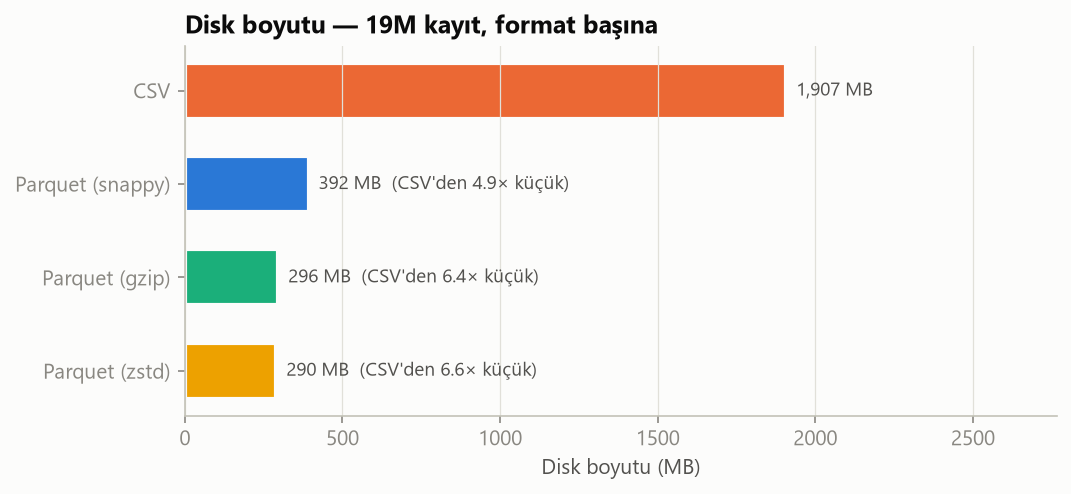

In [4]:
display(Image(pio.plot_disk_size(summary, config.FIGURES_DIR)))

**Neden Parquet 5–6,6 kat küçük?**
1. **Kolon bazlı depolama:** Aynı kolonun değerleri yan yana durur. `VendorID`, `payment_type`, `RatecodeID` gibi kolonlarda yalnızca birkaç farklı değer var; bunlar art arda dizildiğinde çok iyi sıkışır.
2. **Encoding:** Parquet sıkıştırmadan *önce* dictionary encoding (tekrarlanan değeri küçük bir indeksle saklar) ve RLE (art arda aynı değeri "değer × tekrar sayısı" olarak saklar) uygular. `mta_tax` gibi neredeyse hep 0,5 olan bir kolon birkaç bayta iner.
3. **İkili (binary) tipler:** CSV'de `2026-01-01 00:50:40` 19 karakter = 19 bayt; Parquet'te bu bir 8 baytlık tamsayıdır. `12.1` gibi ücretler de metin yerine 8 baytlık sayı.
4. **Codec farkı:** gzip ve zstd, snappy'den ~%25 daha küçük; çünkü snappy sıkıştırma oranı yerine *hız* için tasarlanmıştır. zstd gzip kadar küçültür ama (aşağıda görüleceği gibi) daha hızlı açılır.

## 3. Okuma süresi

**Ölçüm yöntemi (adil karşılaştırma için):**
- Her okuma **aynı tipli tabloyu** üretir: pandas CSV'de tarih kolonları parse edilir, Spark'a CSV için Parquet'in şeması verilir.
- Spark okuması `noop` yazımıyla tetiklenir. `count()` kullanılmadı: Parquet'te `count()` veriyi hiç okumaz, satır sayısını dosya metadata'sından alır — Parquet'i olduğundan çok hızlı gösterirdi.
- Her kombinasyon: 1 ısınma (atılır) + 3 tekrar; her pandas okuması **ayrı süreçte**. Ölçümler sıcak işletim sistemi önbelleğiyle (dosya RAM'de) alındı; soğuk diskte CSV'nin dezavantajı daha da büyür.
- Her okumanın satır sayısı manifest ile doğrulandı (85 kombinasyon, 0 hata).

In [5]:
read = summary[summary["mode"] == "all"].pivot_table(index=["engine", "format"], columns="size", values="seconds_mean")
read[["100k", "1m", "5m", "10m", "full"]]

size                   100k   1m    5m   10m  full
engine format                                     
pandas csv             0.40 3.70 19.42 40.13 71.06
       parquet_gzip    0.06 0.15  0.58  1.10  2.08
       parquet_snappy  0.07 0.16  0.53  1.01  1.75
       parquet_zstd    0.06 0.15  0.53  1.00  2.00
spark  csv             0.35 0.78  2.86  5.06  8.08
       parquet_gzip    0.30 0.94  3.32  5.24  5.19
       parquet_snappy  0.28 0.69  2.39  3.16  3.74
       parquet_zstd    0.30 0.78  2.69  4.56  4.42

### Grafik 2 — Okuma süresi veri boyutuyla nasıl büyüyor?

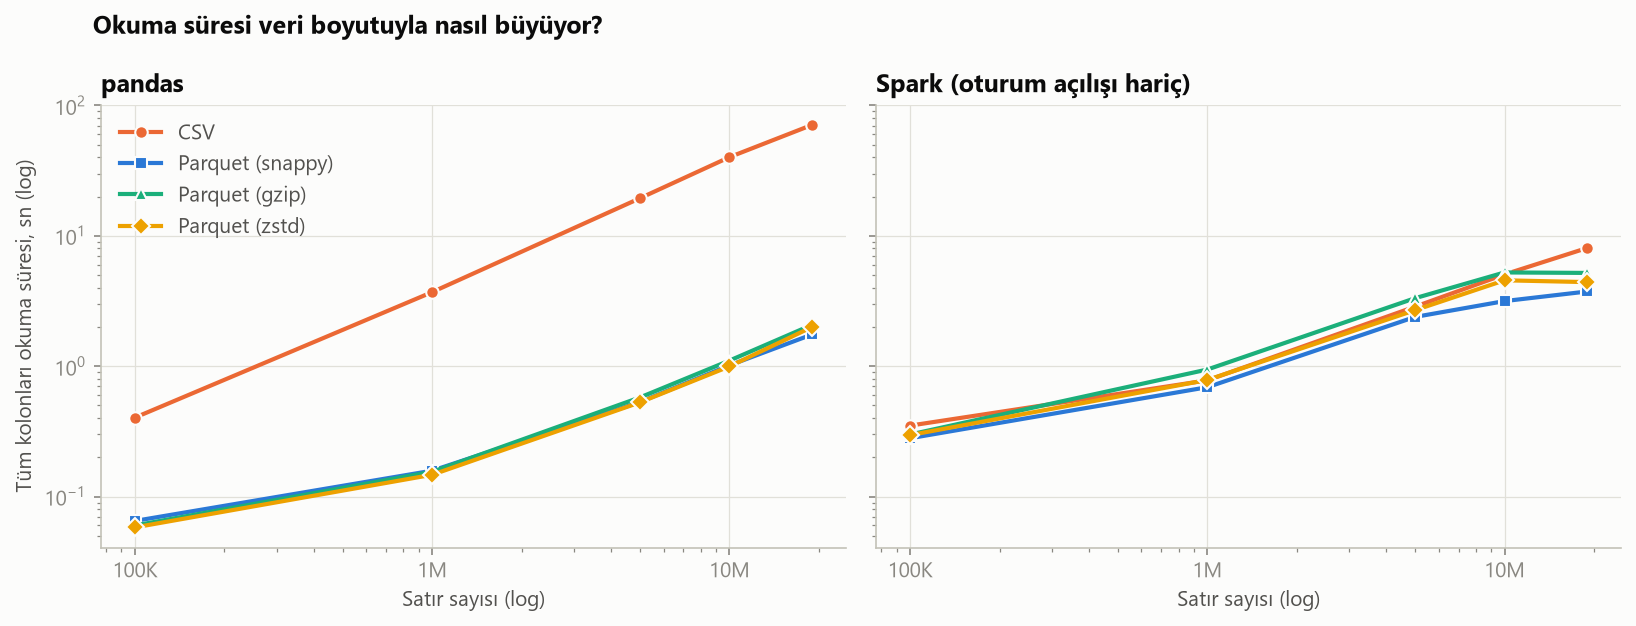

In [6]:
display(Image(pio.plot_read_time(summary, config.FIGURES_DIR)))

**Neden pandas + CSV bu kadar yavaş (19M'de 71 sn, Parquet'te 1,8 sn → ~40 kat)?**
- CSV **metindir**: her hücre karakter karakter taranır, ayraç aranır, sayıya/tarihe çevrilir. 19M × 20 = 380 milyon hücrenin hepsi parse edilir.
- CSV'de **şema yoktur**: pandas her kolonun tipini veriye bakarak tahmin eder; tarih kolonları ayrıca parse edilir.
- pandas'ın varsayılan CSV okuyucusu **tek çekirdek** kullanır; 28 çekirdeğin 27'si boştadır.
- Parquet'te değerler zaten ikili ve tiplidir; pyarrow'un C++ okuyucusu **çok iş parçacıklı** çalışır ve kolon bloklarını doğrudan belleğe kopyalar.

**Neden Spark'ta format farkı küçük?** Spark CSV'yi 28 çekirdeğe bölerek paralel parse eder (CSV satır satır bölünebilir). Parse maliyeti hâlâ var ama 28'e bölünür; bu yüzden Spark CSV (8,1 sn) pandas CSV'den (71 sn) ~9 kat hızlı.

**Şaşırtıcı sonuç — pandas + Parquet, Spark + Parquet'ten hızlı (1,8 sn vs 3,7 sn):** Tek makinede ve RAM'e sığan veride Spark'ın JVM, görev planlama ve satır bazlı iç format maliyeti, pyarrow'un doğrudan kolon kopyalamasını geçer. Ayrıca Spark tek bir Parquet dosyasını en fazla *row group* sayısı kadar (burada 1–4) görevle gerçekten okuyabilir; planlanan partition sayısı (28) gerçek paralelliği yansıtmaz.

**Şemasızlığın bedeli:** Spark CSV'de şema verilmeyip `inferSchema` istenirse okuma ~2 katına çıkar (19M'de 8,1 → 15,7 sn), çünkü tipleri bulmak için dosya bir kez daha baştan sona taranır.

In [7]:
summary[(summary["engine"] == "spark") & (summary["format"] == "csv") & (summary["mode"] != "3cols")] \
    .pivot_table(index="mode", columns="size", values="seconds_mean")[["100k", "1m", "5m", "10m", "full"]]

size,100k,1m,5m,10m,full
mode,,,,,
all,0.35,0.78,2.86,5.06,8.08
all_infer,0.59,1.14,4.87,8.09,15.67


### Grafik 3 — Spark'ın açılış maliyeti hangi boyutta geri kazanılıyor?

Yukarıdaki Spark süreleri **oturum açılışını içermez**. Gerçek bir analizde Spark'ı başlatmak (JVM + SparkContext) de bedeldir; soğuk süreçte ölçüldü (3 tekrar).

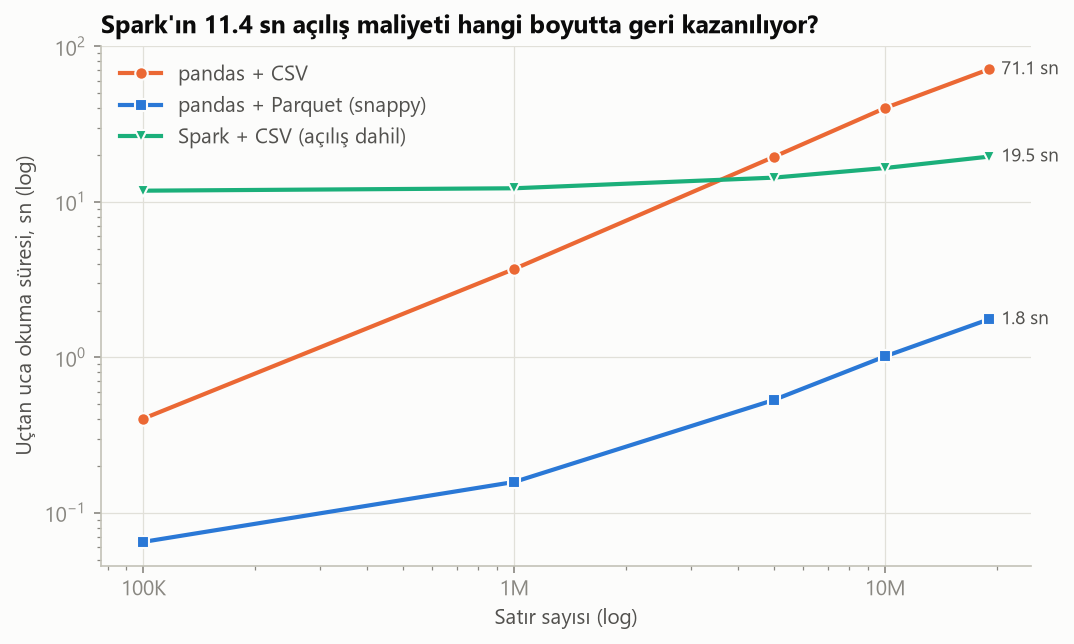

pandas + CSV ile Spark + CSV (açılış dahil) kesişimi ≈ 3.6M kayıt


In [8]:
display(Image(pio.plot_end_to_end(summary, startup_s, config.FIGURES_DIR)))

def crossover_rows(summary, startup_s):
    sel = lambda e, f: summary.query("engine == @e and format == @f and mode == 'all'").sort_values("rows")
    p, s = sel("pandas", "csv"), sel("spark", "csv")
    gap = np.log(p["seconds_mean"].values) - np.log(s["seconds_mean"].values + startup_s)
    i = np.argmax(gap > 0)  # pandas'ın ilk kez daha yavaş olduğu boyut
    x0, x1 = np.log(p["rows"].values[i - 1]), np.log(p["rows"].values[i])
    return float(np.exp(x0 + (x1 - x0) * (-gap[i - 1]) / (gap[i] - gap[i - 1])))

print(f"pandas + CSV ile Spark + CSV (açılış dahil) kesişimi ≈ {crossover_rows(summary, startup_s) / 1e6:.1f}M kayıt")

**Yorum:**
- **~3,6M kayıtın altında** pandas + CSV, Spark'ı başlatmaktan bile hızlıdır: 11,4 sn'lik sabit açılış maliyeti küçük veride geri kazanılamaz.
- **~3,6M'nin üstünde** Spark öne geçer ve fark büyür (19M'de 19,5 sn vs 71 sn). pandas'ın süresi satır sayısıyla doğrusal artarken Spark'ınki paralellik sayesinde çok daha yavaş artar (grafikte neredeyse yatay).
- **Ama:** pandas + Parquet tüm boyutlarda en hızlı seçenek (19M'de 1,8 sn). Yani bu ölçekte **asıl kazanç motor değiştirmekten değil, format değiştirmekten** gelir. Spark'ın zorunlu hale geldiği yer, verinin RAM'e sığmadığı noktadır (Grafik 4).

## 4. Bellek — klasik yaklaşımın asıl sınırı

pandas tablonun tamamını RAM'e alır. İki ölçü alındı:
- **Tablo boyutu:** okuma bittikten sonra DataFrame'in kapladığı bellek (`memory_usage(deep=True)`).
- **Tepe bellek:** okuma *sırasında* sürecin ulaştığı en yüksek bellek (Windows peak working set). Okuma sırasında ara tamponlar (CSV parser'ı, Arrow tablosu + pandas kopyası) aynı anda bellekte olduğu için bu değer daha yüksektir — RAM'in yetip yetmeyeceğini belirleyen budur.

In [9]:
mem = summary[(summary["engine"] == "pandas") & (summary["mode"] == "all")]
mem.pivot_table(index="format", columns="size", values=["disk_mb", "frame_mb", "peak_mb"])[[
    (m, s) for m in ("disk_mb", "frame_mb", "peak_mb") for s in ("1m", "10m", "full")]]

disk_mb                   frame_mb                   peak_mb  \
size                1m      10m     full       1m      10m     full      1m   
format                                                                        
csv             100.40 1,003.59 1,907.49   194.00 1,939.14 3,685.69  515.55   
parquet_gzip     16.40   160.17   296.04   180.63 1,805.42 3,431.55  332.80   
parquet_snappy   21.86   206.01   392.33   180.63 1,805.42 3,431.55  333.97   
parquet_zstd     15.98   157.04   290.15   180.63 1,805.42 3,431.55  334.63   

                                  
size                10m     full  
format                            
csv            5,137.43 9,436.55  
parquet_gzip   2,961.64 5,670.41  
parquet_snappy 3,078.80 5,815.36  
parquet_zstd   3,018.18 6,585.65

### Grafik 4 — pandas tepe belleği ve RAM sınırı

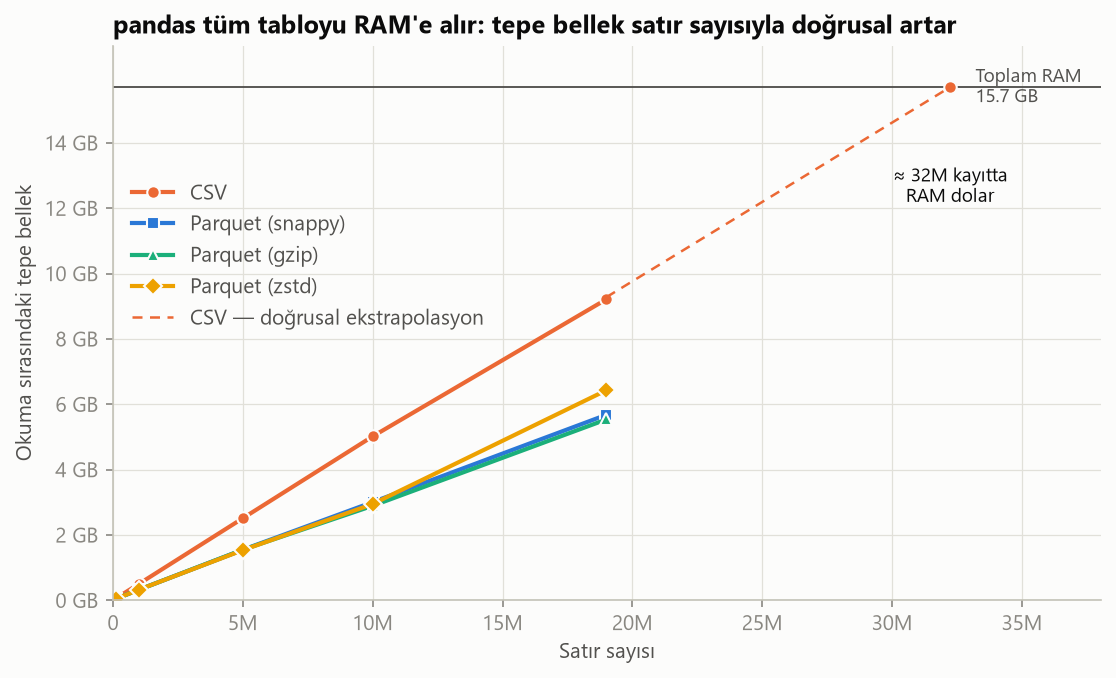

CSV tepe bellek ≈ 497 MB / milyon satır  →  RAM (15.7 GB) ≈ 32.2M satırda dolar


In [10]:
display(Image(pio.plot_pandas_memory(summary, config.FIGURES_DIR)))
csv = mem[mem["format"] == "csv"].sort_values("rows")
fit = pio.linear_fit(csv["rows"], csv["peak_mb"])
import psutil
ram_mb = psutil.virtual_memory().total / 1024**2
print(f"CSV tepe bellek ≈ {fit.slope * 1e6:,.0f} MB / milyon satır  →  RAM ({ram_mb / 1024:.1f} GB) ≈ {fit.rows_at(ram_mb) / 1e6:.1f}M satırda dolar")

**Neden 1,9 GB'lık CSV bellekte 9,4 GB'a çıkıyor (disk boyutunun ~5 katı)?**
1. **Disk → tablo (1,9 → 3,7 GB):** pandas her sayıyı 8 baytlık `float64`/`int64` olarak tutar; CSV'de `1` tek bayt iken bellekte 8 bayttır. `store_and_fwd_flag` gibi metin kolonları her hücre için ayrı bir Python nesnesi (~50 bayt) olarak saklanır.
2. **Tablo → tepe (3,7 → 9,4 GB):** okuma sırasında parser'ın ara tamponları ve kolonların geçici kopyaları tablo ile aynı anda bellekte bulunur.
3. **Parquet neden daha az?** Değerler zaten tipli geldiği için metin parse tamponu yoktur; ama Arrow tablosu ile pandas DataFrame kısa süre aynı anda bellekte durduğundan tepe yine tablonun ~1,7 katıdır.

**Sonuç:** Bellek satır sayısıyla **doğrusal** artıyor (satır başına ~0,5 KB). Bu makinede (15,7 GB RAM) pandas + CSV **~32M kayıtta** RAM'i doldurur; işletim sistemi ve diğer uygulamaların payıyla pratik sınır daha da aşağıdadır. Windows bu noktada hata vermek yerine diske takas (swap) yapar ve okuma onlarca kat yavaşlar. Spark ise veriyi parça parça işler ve gerekirse diske taşar; RAM'den büyük veriyi de işleyebilir — **ölçeklenebilir teknolojinin zorunlu hale geldiği nokta budur.**

## 5. Column pruning — sadece gereken kolonu okumak

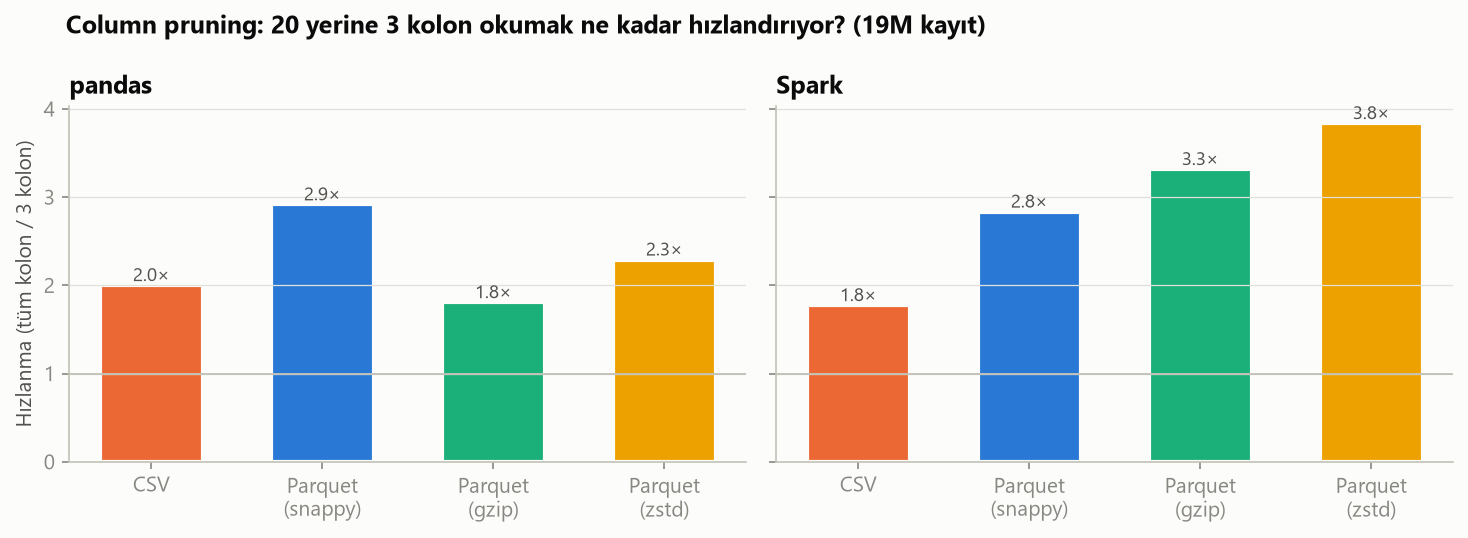

In [11]:
display(Image(pio.plot_column_pruning(summary, config.FIGURES_DIR)))

**Neden Parquet'te kazanç daha büyük?**
- **Parquet:** her kolon dosyada ayrı bir blok olarak durur ve dosyanın sonundaki metadata her bloğun yerini söyler. 3 kolon istenince okuyucu yalnızca o 3 bloğa gider; diğer 17 kolon diskten hiç okunmaz. Spark'ta 3,8 kata varan hızlanma bu yüzden.
- **CSV:** bir satırdaki 3. kolona ulaşmak için önceki kolonların karakterlerini de taramak gerekir; dosyanın tamamı yine okunur. Kazanç yalnızca "okunan metni sayıya çevirmeme"den gelir (~1,8–2×).
- pandas'ta Parquet gzip kazancı düşük (1,8×): gzip'in açılması pahalı ve okuma süresinin büyük kısmı zaten sıkıştırma çözmede geçiyor.

## 6. Araştırma sorusuna cevap (Öğrenci 1 katkısı)

> **Hangi boyutta, hangi formatta klasik yaklaşım yetersiz kalmaya başladı ve neden?**

1. **Format, motordan önce gelir.** Aynı pandas ile CSV yerine Parquet okumak 19M kayıtta 71 sn → 1,8 sn (~40×) ve disk 1,9 GB → 0,3 GB (6,6×). Bu ölçekte en büyük kazanç formattan gelir.
2. **Süre açısından:** pandas + CSV, ~3,6M kayıttan sonra Spark'ın (açılış dahil) gerisine düşer; 19M'de 3,6 kat yavaştır ve fark satır sayısıyla büyür.
3. **Bellek açısından (asıl sınır):** pandas tüm tabloyu RAM'e almak zorunda; tepe bellek satır başına ~0,5 KB ile doğrusal artar. 19M'de RAM'in %59'u kullanıldı; **~32M kayıtta 16 GB RAM tükenir.** Bu noktadan sonra format ne olursa olsun klasik yaklaşım çalışmaz; veriyi parçalayıp paralel ve diske taşabilen bir sistem (Spark) gerekir.
4. **Neden:** CSV metin + şemasız (her hücre parse edilir, tipler tahmin edilir), satır bazlı (column pruning sınırlı), pandas tek çekirdek ve tek parça bellek modeli kullanır. Parquet kolon bazlı, tipli, sıkıştırılmış ve kendi şemasını taşır; Spark işi çekirdeklere böler.

**Sınırlamalar:** Tek makine (28 çekirdek, 15,7 GB RAM, NVMe SSD); ölçümler sıcak işletim sistemi önbelleğiyle; yalnızca **okuma** ölçüldü — groupby/join gibi işleme performansı Öğrenci 5'in kapsamındadır. 32M sınırı doğrusal ekstrapolasyondur, ölçülmemiştir.